In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split



In [7]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [9]:
# 1. Generate a mock binary classification dataset (e.g., imbalanced lead data)
X, y = make_classification(
    n_samples=1000, 
    n_features=5, 
    weights=[0.85, 0.15], # 15% conversion rate
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)



In [10]:
# 2. Train a simple model and get predicted probabilities for the positive class
model = LogisticRegression()
model.fit(X_train, y_train)
y_scores = model.predict_proba(X_test)[:, 1]

# 3. Calculate ROC curve metrics across all thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

# 4. Find the best threshold using Youden's J Statistic (TPR - FPR)
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_threshold = thresholds[best_idx]



/Users/ram/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/ram/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/ram/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/ram/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ram/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ram/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in 

In [ ]:
print(f"Optimal Decision Threshold: {best_threshold:.4f}")
print(f"Corresponding True Positive Rate (Sensitivity): {tpr[best_idx]:.4f}")
print(f"Corresponding False Positive Rate (1 - Specificity): {fpr[best_idx]:.4f}")

# 5. Visualize the ROC Curve and the Optimal Threshold Point


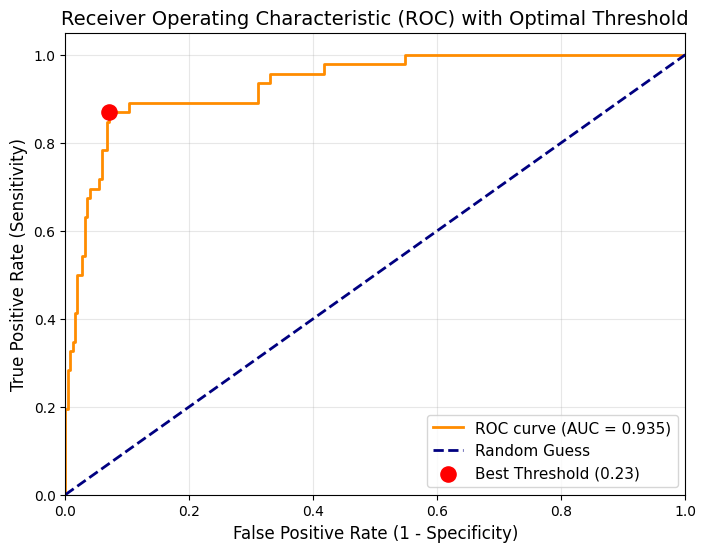

In [11]:
plt.figure(figsize=(8, 6))

# Plot the ROC curve line
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')

# Plot the random guess diagonal line
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

# Highlight the best threshold point on the curve
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', s=120, zorder=5, 
            label=f'Best Threshold ({best_threshold:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) with Optimal Threshold', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.show()